# Q1-Q2: aggregation and directional motion
Muhammad Sami Ul Basit | 25280025

These cells run the exhaustive NumPy checks and generate the ring-road heatmap. Full proofs and the nine-row aggregation table are in the report.

In [1]:
from pathlib import Path
import sys, subprocess, json
from IPython.display import display, Image
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src').is_dir()
def run(script,*args):
    command=[sys.executable,str(ROOT/'src'/script),*args]
    log=ROOT/'results'/(script.replace('.py','')+('_'+args[-1] if args else '')+'.log')
    with log.open('w',encoding='utf-8') as f:
        result=subprocess.run(command,cwd=ROOT,stdout=f,stderr=subprocess.STDOUT)
    print(log.read_text(encoding='utf-8')[-16000:])
    result.check_returncode()
def show(name):
    display(Image(filename=str(ROOT/'figures'/name)))

## Q1: scalar count encoding
An affine message only retains $wS+cn$. For nonlinear encoding take base $B=K+1$ and messages $1,B,B^2$; the three counts are its digits. There are $\binom{11}{3}-1=164$ legal triples when $K=8$. The message $x^2$ counts non-steady neighbors.

In [2]:
run('theory.py')
print((ROOT/'results'/'theory_checks.json').read_text())

Verified 164 encodings and exact bidirectional history rule; saved Q2 heatmaps.

{
  "K": 8,
  "base": 9,
  "triples": 164,
  "unique_codes": 164,
  "exact_decode": true,
  "history_max_errors": [
    2.220446049250313e-16,
    2.220446049250313e-16
  ],
  "symmetric_single_impulse_sse": 0.5
}


## Q2: direction
The equal-neighbor least-squares fit minimizes $a^2+(b-1)^2+b^2$, giving $a=0,b=1/2$. Directional weights $[0,0,1]$ exactly shift against traffic. With history, $[a,b,c]=[0,1,-1]$ predicts either direction because the previous local value equals the current value at the already-visited neighbor.

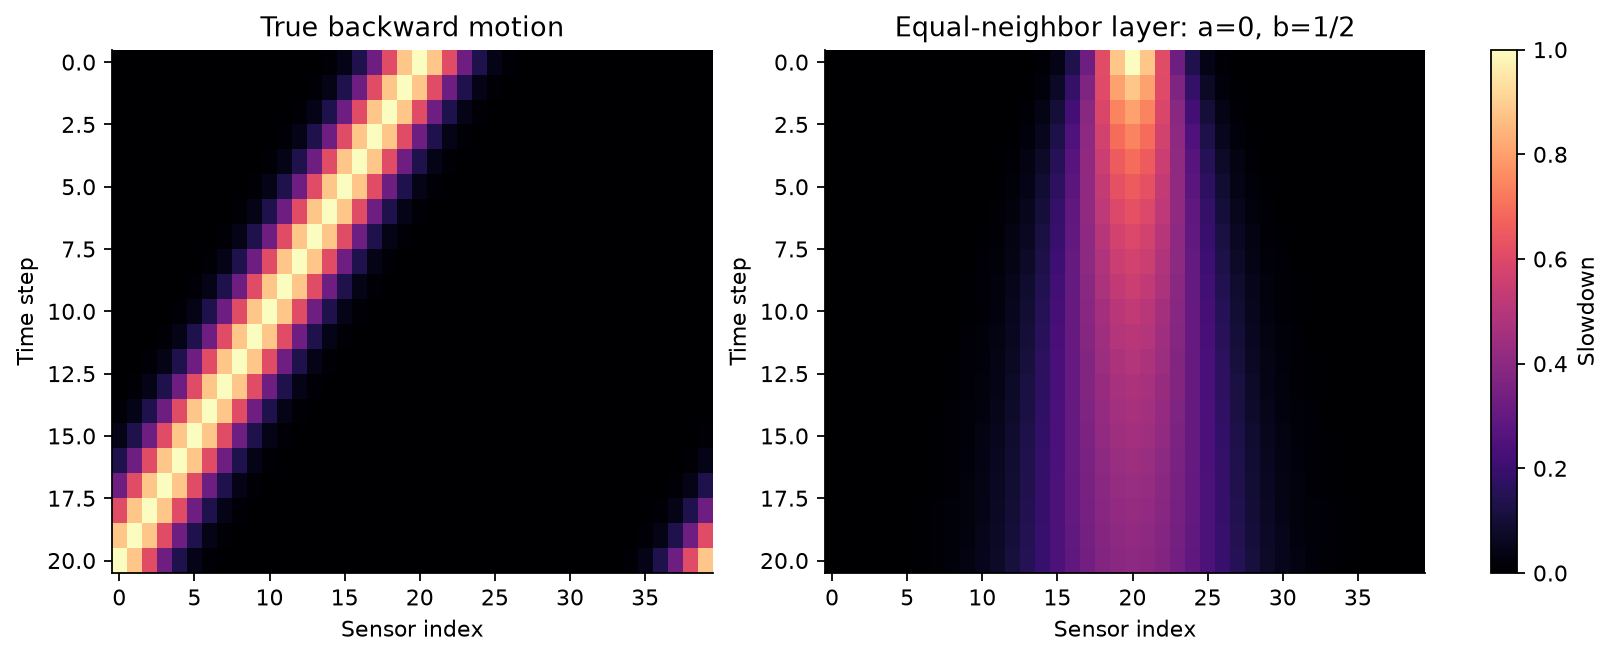

In [3]:
show('q2_rollouts.png')